# Exploratory Data Analysis of Global Economic Indicators

### **Exploratory Data Analysis of Global Economic Indicators** analyses World Bank data for 217 countries from 2000 to 2023, covering GDP, population, life expectancy, unemployment and energy use. It finds that a large economy does not mean high income per person, and that GDP per capita is strongly linked to life expectancy.

In [1]:
import pandas as pd
import os, shutil

# Make folders
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/clean", exist_ok=True)

# Copy original files into the raw backup folder
for f in ["WDICSV.csv", "WDICountry.csv", "WDISeries.csv"]:
    shutil.copy(f, f"data/raw/{f}")

print(os.listdir("data/raw"))

['WDICountry.csv', 'WDICSV.csv', 'WDISeries.csv']


In [2]:
wdi = pd.read_csv("data/raw/WDICSV.csv")          # main data
country = pd.read_csv("data/raw/WDICountry.csv")  # country info

print("Raw shape:", wdi.shape)
print(wdi.columns.tolist()[:8])       # first few column names
print(country.columns.tolist()[:8])   # first few column names

Raw shape: (396970, 70)
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963']
['Country Code', 'Short Name', 'Table Name', 'Long Name', '2-alpha code', 'Currency Unit', 'Special Notes', 'Region']


In [3]:
# Real countries have a Region; aggregates have it empty
print("Income Group column exists:", "Income Group" in country.columns)

real = country[country["Region"].notna()][["Country Code", "Region", "Income Group"]]
print("Real countries:", real.shape[0])

# Keep only real countries and attach Region and Income Group
df = wdi.merge(real, on="Country Code", how="inner")

print("Shape after merge:", df.shape)
print("Countries left:", df["Country Name"].nunique())

Income Group column exists: True
Real countries: 217
Shape after merge: (325066, 72)
Countries left: 217


In [4]:
# Indicator code -> readable name
names = {
    "NY.GDP.MKTP.CD": "gdp_total",
    "NY.GDP.PCAP.KD": "gdp_per_capita",
    "SP.POP.TOTL": "population",
    "NY.GNP.PCAP.CD": "gni_per_capita",
    "EG.USE.PCAP.KG.OE": "energy_use",
    "SP.DYN.LE00.IN": "life_expectancy",
    "SL.UEM.TOTL.ZS": "unemployment",
}

df = df[df["Indicator Code"].isin(names.keys())]

print("Rows now:", df.shape[0])
print(df["Indicator Code"].value_counts())

Rows now: 1519
Indicator Code
EG.USE.PCAP.KG.OE    217
NY.GDP.MKTP.CD       217
NY.GDP.PCAP.KD       217
NY.GNP.PCAP.CD       217
SP.DYN.LE00.IN       217
SP.POP.TOTL          217
SL.UEM.TOTL.ZS       217
Name: count, dtype: int64


In [5]:
years = [str(y) for y in range(2000, 2024)]

df = df.melt(
    id_vars=["Country Name", "Country Code", "Region", "Income Group", "Indicator Code"],
    value_vars=years,
    var_name="Year",
    value_name="Value"
)

print("Shape:", df.shape)
print(df.head())

Shape: (36456, 7)
  Country Name Country Code                      Region Income Group  \
0  Afghanistan          AFG  Middle East & North Africa   Low income   
1  Afghanistan          AFG  Middle East & North Africa   Low income   
2  Afghanistan          AFG  Middle East & North Africa   Low income   
3  Afghanistan          AFG  Middle East & North Africa   Low income   
4  Afghanistan          AFG  Middle East & North Africa   Low income   

      Indicator Code  Year         Value  
0  EG.USE.PCAP.KG.OE  2000           NaN  
1     NY.GDP.MKTP.CD  2000  3.521418e+09  
2     NY.GDP.PCAP.KD  2000  3.083183e+02  
3     NY.GNP.PCAP.CD  2000           NaN  
4     SP.DYN.LE00.IN  2000  5.500500e+01  


In [6]:
# Turn indicator rows into columns
df = df.pivot_table(
    index=["Country Name", "Country Code", "Region", "Income Group", "Year"],
    columns="Indicator Code",
    values="Value"
).reset_index()

df.columns.name = None          # remove extra label
df = df.rename(columns=names)   # use readable names
df["Year"] = df["Year"].astype(int)

print("Shape:", df.shape)
print(df.columns.tolist())
df.head()

Shape: (5208, 12)
['Country Name', 'Country Code', 'Region', 'Income Group', 'Year', 'energy_use', 'gdp_total', 'gdp_per_capita', 'gni_per_capita', 'unemployment', 'life_expectancy', 'population']


,Country Name,Country Code,Region,Income Group,Year,energy_use,gdp_total,gdp_per_capita,gni_per_capita,unemployment,life_expectancy,population
0,Afghanistan,AFG,Middle East & North Africa,Low income,2000,NaN,3.521418e+09,308.318270,NaN,7.897,55.005,20130327.0
1,Afghanistan,AFG,Middle East & North Africa,Low income,2001,NaN,2.813572e+09,277.118051,NaN,7.973,55.511,20284307.0
2,Afghanistan,AFG,Middle East & North Africa,Low income,2002,NaN,3.825701e+09,338.139974,180.0,7.867,56.225,21378117.0
3,Afghanistan,AFG,Middle East & North Africa,Low income,2003,NaN,4.520947e+09,346.071627,190.0,7.844,57.171,22733049.0
4,Afghanistan,AFG,Middle East & North Africa,Low income,2004,NaN,5.224897e+09,338.637274,210.0,7.794,57.810,23560654.0


In [7]:
# Count of missing values per column
print(df.isnull().sum())

# Percentage missing per column
print((df.isnull().mean() * 100).round(1))

Country Name          0
Country Code          0
Region                0
Income Group          0
Year                  0
energy_use         1522
gdp_total           166
gdp_per_capita      248
gni_per_capita      464
unemployment        724
life_expectancy       0
population            0
dtype: int64
Country Name        0.0
Country Code        0.0
Region              0.0
Income Group        0.0
Year                0.0
energy_use         29.2
gdp_total           3.2
gdp_per_capita      4.8
gni_per_capita      8.9
unemployment       13.9
life_expectancy     0.0
population          0.0
dtype: float64


In [8]:
cols = ["energy_use", "gdp_total", "gdp_per_capita",
        "gni_per_capita", "unemployment", "life_expectancy", "population"]

# Sort so each country's years are in order
df = df.sort_values(["Country Name", "Year"]).reset_index(drop=True)

# Fill only gaps BETWEEN known values (no guessing at the start or end)
df[cols] = df.groupby("Country Name")[cols].transform(
    lambda s: s.interpolate(limit_area="inside")
)

print(df[cols].isnull().sum())
print((df[cols].isnull().mean() * 100).round(1))

energy_use         1522
gdp_total           158
gdp_per_capita      248
gni_per_capita      442
unemployment        724
life_expectancy       0
population            0
dtype: int64
energy_use         29.2
gdp_total           3.0
gdp_per_capita      4.8
gni_per_capita      8.5
unemployment       13.9
life_expectancy     0.0
population          0.0
dtype: float64


In [9]:
# 1. Countries with NO data at all for each column
all_missing = df.groupby("Country Name")[cols].apply(lambda g: g.isnull().all())
print("Countries with no data at all:")
print(all_missing.sum())

# 2. Missing values by year for the two biggest gaps
print(df.groupby("Year")[["energy_use", "unemployment"]].apply(lambda g: g.isnull().sum()))

Countries with no data at all:
energy_use         39
gdp_total           3
gdp_per_capita      4
gni_per_capita     10
unemployment       30
life_expectancy     0
population          0
dtype: int64
      energy_use  unemployment
Year                          
2000          69            30
2001          69            30
2002          69            30
2003          69            30
2004          41            30
2005          40            30
2006          40            30
2007          40            30
2008          68            30
2009          68            30
2010          68            30
2011          68            30
2012          67            30
2013          67            30
2014          67            30
2015          68            30
2016          68            30
2017          68            30
2018          68            30
2019          68            30
2020          68            30
2021          68            30
2022          68            31
2023          68           

In [10]:
# Countries with no GDP data at all
no_gdp = all_missing[all_missing["gdp_total"] | all_missing["gdp_per_capita"]]
print("Countries with no GDP data:")
print(no_gdp.index.tolist())

# How complete is 2022 for the key columns?
latest = df[df["Year"] == 2022]
print("\nMissing in 2022 out of", len(latest), "countries:")
print(latest[cols].isnull().sum())

Countries with no GDP data:
['British Virgin Islands', 'Gibraltar', "Korea, Dem. People's Rep.", 'St. Martin (French part)']

Missing in 2022 out of 217 countries:
energy_use         68
gdp_total           8
gdp_per_capita      9
gni_per_capita     16
unemployment       31
life_expectancy     0
population          0
dtype: int64


In [11]:
# 1. Duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# 2. Data types
print(df.dtypes)

# 3. Save the clean file
df.to_csv("data/clean/world_indicators_clean.csv", index=False)
print("Saved:", os.listdir("data/clean"))

# 4. Before vs after summary (for your report)
print("\nRaw shape  :", wdi.shape)
print("Clean shape:", df.shape)
print("Countries  :", df["Country Name"].nunique())
print("Years      :", df["Year"].min(), "to", df["Year"].max())

Duplicate rows: 0
Country Name           str
Country Code           str
Region                 str
Income Group           str
Year                 int64
energy_use         float64
gdp_total          float64
gdp_per_capita     float64
gni_per_capita     float64
unemployment       float64
life_expectancy    float64
population         float64
dtype: object
Saved: ['world_indicators_clean.csv']

Raw shape  : (396970, 70)
Clean shape: (5208, 12)
Countries  : 217
Years      : 2000 to 2023


### Q1 Which countries have the highest GDP?

            Country Name  gdp_trillion_usd
4966       United States             26.05
1006               China             18.32
2374               Japan              4.45
1774             Germany              4.20
2158               India              3.25
4942      United Kingdom              3.18
1654              France              2.79
3886  Russian Federation              2.29
862               Canada              2.20
2326               Italy              2.10


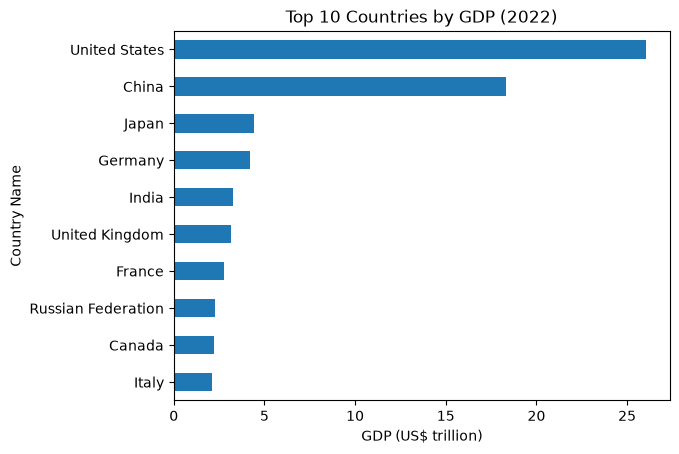

In [12]:
import matplotlib.pyplot as plt

# Load the clean file
df = pd.read_csv("data/clean/world_indicators_clean.csv")

# Use 2022 for country comparisons (most complete recent year)
latest = df[df["Year"] == 2022]

# Top 10 by total GDP, shown in trillions of US$
top_gdp = latest.nlargest(10, "gdp_total")[["Country Name", "gdp_total"]].copy()
top_gdp["gdp_trillion_usd"] = (top_gdp["gdp_total"] / 1e12).round(2)
print(top_gdp[["Country Name", "gdp_trillion_usd"]])

# Bar chart
top_gdp.plot(kind="barh", x="Country Name", y="gdp_trillion_usd", legend=False)
plt.title("Top 10 Countries by GDP (2022)")
plt.xlabel("GDP (US$ trillion)")
plt.gca().invert_yaxis()
plt.show()

### Q2: Which countries have the highest GDP per capita?

         Country Name  gdp_per_capita
3142           Monaco        214360.0
526           Bermuda        109412.0
2806       Luxembourg        107467.0
2254          Ireland         97794.0
4534      Switzerland         93360.0
2278      Isle of Man         86101.0
3550           Norway         83757.0
886    Cayman Islands         79942.0
4126        Singapore         68271.0
958   Channel Islands         67509.0


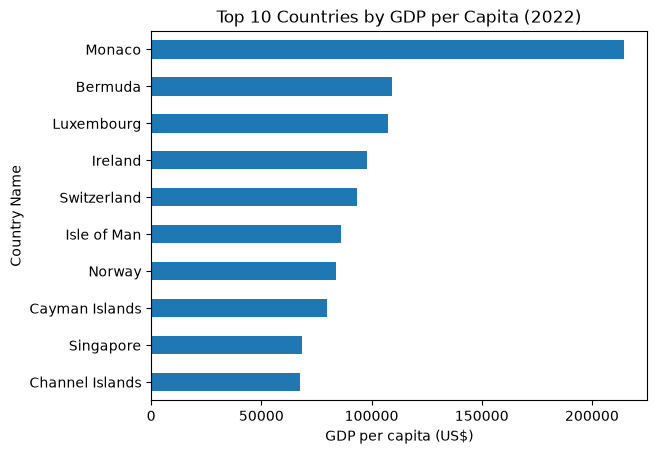

In [13]:
# Top 10 by GDP per capita (constant US$)
top_pc = latest.nlargest(10, "gdp_per_capita")[["Country Name", "gdp_per_capita"]].copy()
top_pc["gdp_per_capita"] = top_pc["gdp_per_capita"].round(0)
print(top_pc)

# Bar chart
top_pc.plot(kind="barh", x="Country Name", y="gdp_per_capita", legend=False)
plt.title("Top 10 Countries by GDP per Capita (2022)")
plt.xlabel("GDP per capita (US$)")
plt.gca().invert_yaxis()
plt.show()

### Q3: How has India's GDP changed over time?

      Year  gdp_trillion_usd
2136  2000              0.47
2137  2001              0.49
2138  2002              0.51
2139  2003              0.61
2140  2004              0.71
2141  2005              0.82
2142  2006              0.94
2143  2007              1.22
2144  2008              1.20
2145  2009              1.34
2146  2010              1.68
2147  2011              1.82
2148  2012              1.83
2149  2013              1.86
2150  2014              2.04
2151  2015              2.10
2152  2016              2.29
2153  2017              2.65
2154  2018              2.70
2155  2019              2.84
2156  2020              2.67
2157  2021              3.17
2158  2022              3.25
2159  2023              3.50


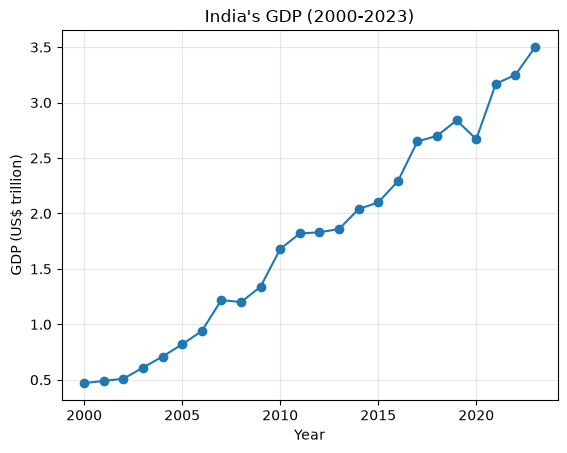

In [14]:
# India's total GDP, 2000-2023, in US$ trillion
india = df[df["Country Name"] == "India"].copy()
india["gdp_trillion_usd"] = (india["gdp_total"] / 1e12).round(2)
print(india[["Year", "gdp_trillion_usd"]])

# Line chart
plt.plot(india["Year"], india["gdp_trillion_usd"], marker="o")
plt.title("India's GDP (2000-2023)")
plt.xlabel("Year")
plt.ylabel("GDP (US$ trillion)")
plt.grid(alpha=0.3)
plt.show()


### Q4: Which countries experienced the largest GDP growth?

                       gdp_2000      gdp_2022  growth_pct
Country Name                                             
Guyana             7.126679e+08  1.471839e+10      1965.0
Mongolia           1.136896e+09  1.714647e+10      1408.0
China              1.223755e+12  1.831677e+13      1397.0
Azerbaijan         5.272616e+09  7.880747e+10      1395.0
Ethiopia           8.242350e+09  1.231403e+11      1394.0
Ghana              4.982851e+09  7.391900e+10      1383.0
Angola             9.129595e+09  1.282340e+11      1305.0
Qatar              1.775989e+10  2.357093e+11      1227.0
Viet Nam           3.117252e+10  4.134452e+11      1226.0
Equatorial Guinea  1.045998e+09  1.368764e+10      1209.0


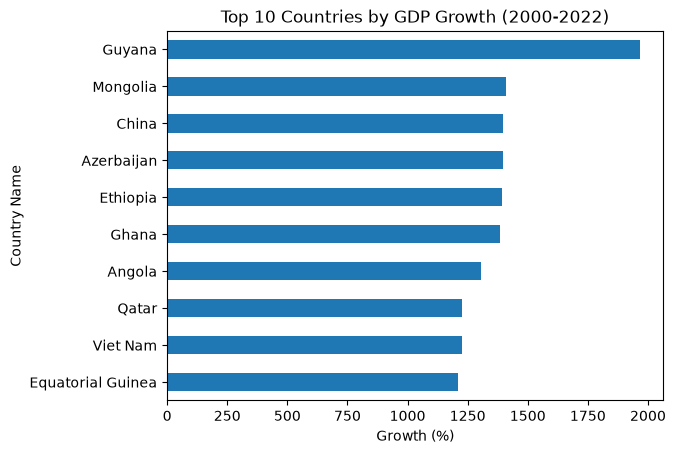

In [15]:
# GDP in 2000 and 2022 for each country
start = df[df["Year"] == 2000].set_index("Country Name")["gdp_total"]
end = df[df["Year"] == 2022].set_index("Country Name")["gdp_total"]

# Percentage growth from 2000 to 2022 (drop countries with missing values)
growth = pd.DataFrame({"gdp_2000": start, "gdp_2022": end}).dropna()
growth["growth_pct"] = ((growth["gdp_2022"] - growth["gdp_2000"]) / growth["gdp_2000"] * 100).round(0)

top_growth = growth.nlargest(10, "growth_pct")
print(top_growth)

# Bar chart
top_growth["growth_pct"].plot(kind="barh")
plt.title("Top 10 Countries by GDP Growth (2000-2022)")
plt.xlabel("Growth (%)")
plt.gca().invert_yaxis()
plt.show()

### Q5: How does population relate to GDP?

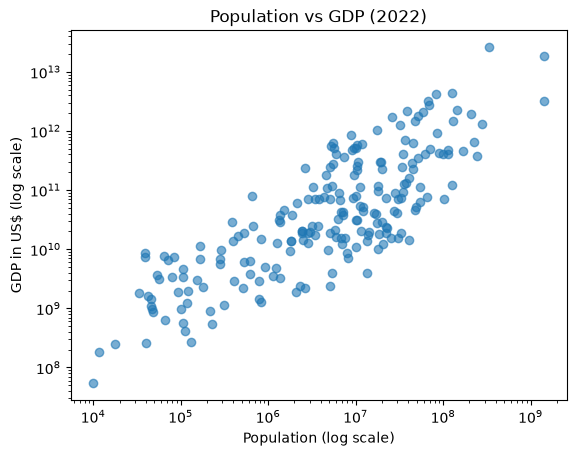

            population  gdp_total
population    1.000000   0.813708
gdp_total     0.813708   1.000000


In [19]:
# Population vs total GDP for 2022
plt.scatter(latest["population"], latest["gdp_total"], alpha=0.6)
plt.xscale("log")   # log scale because values vary hugely
plt.yscale("log")
plt.xlabel("Population (log scale)")
plt.ylabel("GDP in US$ (log scale)")
plt.title("Population vs GDP (2022)")
plt.show()

# Correlation (log values handle the huge range better)
print(np.log10(latest[["population", "gdp_total"]]).corr())

In [18]:
import numpy as np

# Correlation on log values (handles the huge range better)
print(np.log10(latest[["population", "gdp_total"]]).corr())

            population  gdp_total
population    1.000000   0.813708
gdp_total     0.813708   1.000000


### Q6: Is GDP per capita associated with life expectancy?

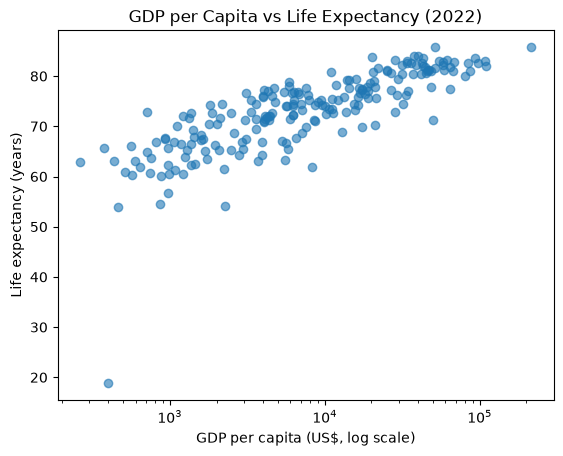

                    log_gdp_per_capita  life_expectancy
log_gdp_per_capita            1.000000         0.797949
life_expectancy               0.797949         1.000000


In [20]:
# GDP per capita vs life expectancy for 2022
plt.scatter(latest["gdp_per_capita"], latest["life_expectancy"], alpha=0.6)
plt.xscale("log")   # log scale because incomes vary hugely
plt.xlabel("GDP per capita (US$, log scale)")
plt.ylabel("Life expectancy (years)")
plt.title("GDP per Capita vs Life Expectancy (2022)")
plt.show()

# Correlation (log of GDP per capita vs life expectancy)
pc = latest[["gdp_per_capita", "life_expectancy"]].dropna()
pc["log_gdp_per_capita"] = np.log10(pc["gdp_per_capita"])
print(pc[["log_gdp_per_capita", "life_expectancy"]].corr())

In [21]:
# Find the countries with the lowest life expectancy in 2022
print(latest.nsmallest(5, "life_expectancy")[["Country Name", "life_expectancy", "gdp_per_capita"]])

                  Country Name  life_expectancy  gdp_per_capita
910   Central African Republic           18.818      398.915398
4246        Somalia, Fed. Rep.           53.931      460.046227
3478                   Nigeria           54.079     2254.290804
934                       Chad           54.528      862.602128
2686                   Lesotho           56.812      967.519286


In [22]:
# 1. CAR life expectancy over time
car = df[df["Country Name"] == "Central African Republic"]
print(car[["Year", "life_expectancy"]].tail(8))

# 2. Correlation with and without CAR (2022)
pc = latest[["Country Name", "gdp_per_capita", "life_expectancy"]].dropna().copy()
pc["log_gdp_per_capita"] = np.log10(pc["gdp_per_capita"])

with_car = pc[["log_gdp_per_capita", "life_expectancy"]].corr().iloc[0, 1]
without_car = pc[pc["Country Name"] != "Central African Republic"][["log_gdp_per_capita", "life_expectancy"]].corr().iloc[0, 1]

print("Correlation with CAR   :", round(with_car, 3))
print("Correlation without CAR:", round(without_car, 3))

     Year  life_expectancy
904  2016           50.999
905  2017           45.231
906  2018           52.297
907  2019           31.530
908  2020           50.596
909  2021           40.279
910  2022           18.818
911  2023           57.408
Correlation with CAR   : 0.798
Correlation without CAR: 0.841


### Q7: How does unemployment vary across countries?

Highest unemployment:
                        Country Name  unemployment
1534                        Eswatini        36.472
4270                    South Africa        33.268
1318                        Djibouti        26.272
5134              West Bank and Gaza        24.420
622                         Botswana        23.615
1702                           Gabon        20.319
1102                     Congo, Rep.        20.131
3286                         Namibia        19.615
4438  St. Vincent and the Grenadines        19.277
2734                           Libya        19.238

Lowest unemployment:
         Country Name  unemployment
3838            Qatar         0.130
814          Cambodia         0.245
3454            Niger         0.403
766           Burundi         0.909
3118          Moldova         0.909
4630         Thailand         0.940
934              Chad         1.081
2614          Lao PDR         1.209
358           Bahrain         1.265
4222  Solomon Islands         1.475

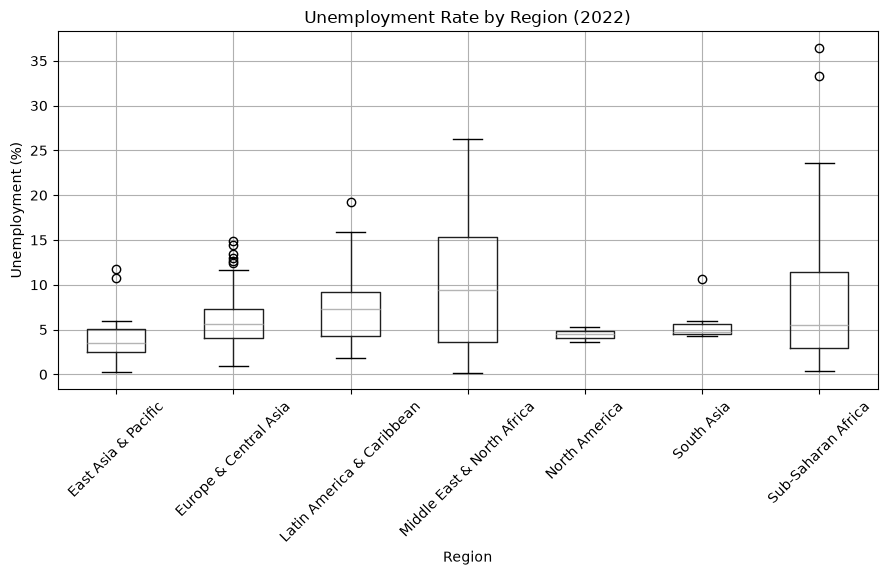

In [23]:
# Highest and lowest unemployment in 2022 (31 countries have no data)
unemp = latest[["Country Name", "Region", "unemployment"]].dropna()
print("Highest unemployment:")
print(unemp.nlargest(10, "unemployment")[["Country Name", "unemployment"]])
print("\nLowest unemployment:")
print(unemp.nsmallest(10, "unemployment")[["Country Name", "unemployment"]])

# Spread by region
unemp.boxplot(column="unemployment", by="Region", rot=45, figsize=(9, 6))
plt.suptitle("")
plt.title("Unemployment Rate by Region (2022)")
plt.ylabel("Unemployment (%)")
plt.tight_layout()
plt.show()

### Q8: Which countries have high GDP but relatively low GDP per capita?

     Country Name  gdp_trillion_usd    population  gdp_per_person
2158        India              3.25  1.425423e+09          2280.0
2182    Indonesia              1.32  2.788305e+08          4731.0
646        Brazil              1.95  2.103064e+08          9281.0
4774      Turkiye              0.93  8.497991e+07         10898.0
3070       Mexico              1.47  1.286131e+08         11406.0


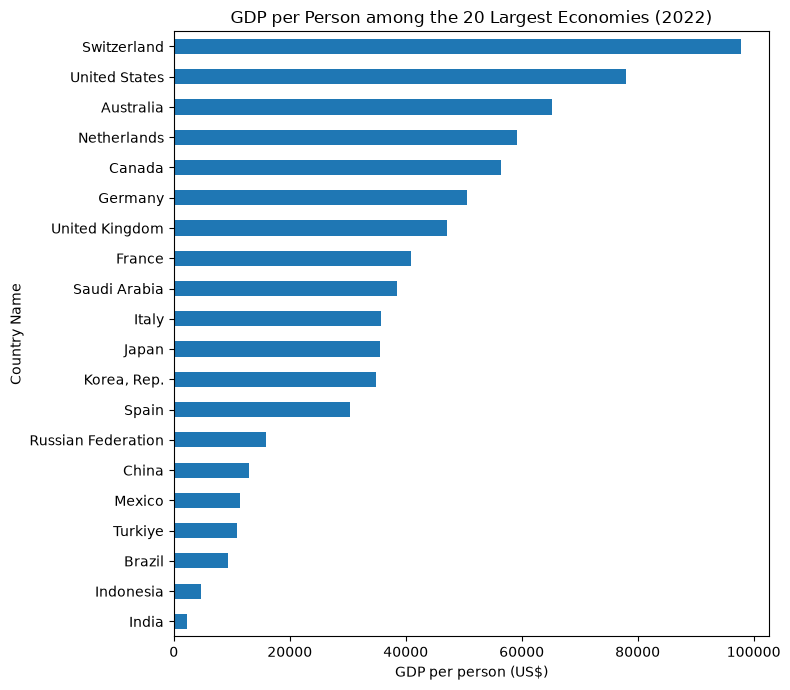

In [24]:
# Per-person GDP using the same measure (current US$) as total GDP
latest = latest.copy()
latest["gdp_per_person"] = (latest["gdp_total"] / latest["population"]).round(0)

# Take the 20 biggest economies, then find those with the lowest GDP per person
big20 = latest.nlargest(20, "gdp_total")
low_pc = big20.nsmallest(5, "gdp_per_person")[["Country Name", "gdp_total", "population", "gdp_per_person"]].copy()
low_pc["gdp_trillion_usd"] = (low_pc["gdp_total"] / 1e12).round(2)
print(low_pc[["Country Name", "gdp_trillion_usd", "population", "gdp_per_person"]])

# Bar chart of GDP per person among the top 20 economies
big20.sort_values("gdp_per_person").plot(
    kind="barh", x="Country Name", y="gdp_per_person", legend=False, figsize=(8, 7))
plt.title("GDP per Person among the 20 Largest Economies (2022)")
plt.xlabel("GDP per person (US$)")
plt.tight_layout()
plt.show()

### Q9: How have selected economic indicators changed over time?

      gdp_per_capita  life_expectancy  unemployment  energy_use
Year                                                           
2000         12435.2             67.6           8.6      2282.1
2005         14149.9             69.2           8.3      2161.6
2010         15546.7             70.8           8.4      2516.9
2015         17068.4             72.1           8.1      2401.0
2020         16149.9             72.5           8.4      2230.8
2023         18205.1             73.8           6.8      2261.1


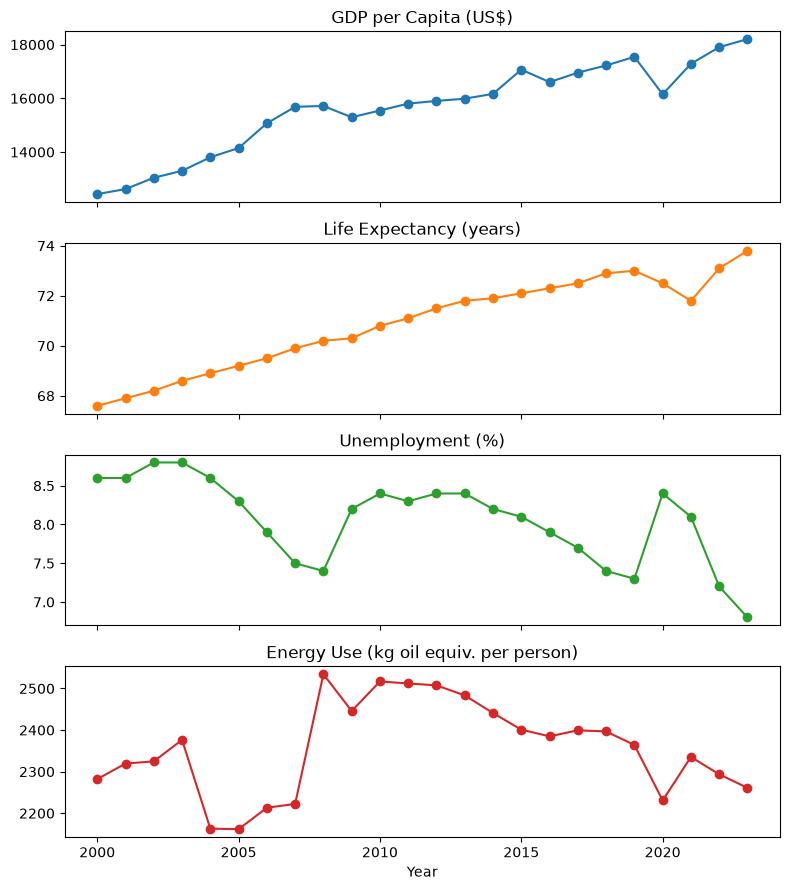

In [25]:
# Average of each indicator across all countries, per year
cols_trend = ["gdp_per_capita", "life_expectancy", "unemployment", "energy_use"]
trend = df.groupby("Year")[cols_trend].mean().round(1)
print(trend.iloc[[0, 5, 10, 15, 20, 23]])   # 2000, 2005, 2010, 2015, 2020, 2023

# One small chart per indicator
trend.plot(subplots=True, figsize=(8, 9), marker="o", legend=False,
           title=["GDP per Capita (US$)", "Life Expectancy (years)",
                  "Unemployment (%)", "Energy Use (kg oil equiv. per person)"])
plt.xlabel("Year")
plt.tight_layout()
plt.show()

### Q10: What correlations exist among GDP, population, unemployment and life expectancy?

                 log_gdp_total  log_population  unemployment  life_expectancy
log_gdp_total             1.00            0.81         -0.22             0.34
log_population            0.81            1.00         -0.17            -0.17
unemployment             -0.22           -0.17          1.00            -0.12
life_expectancy           0.34           -0.17         -0.12             1.00


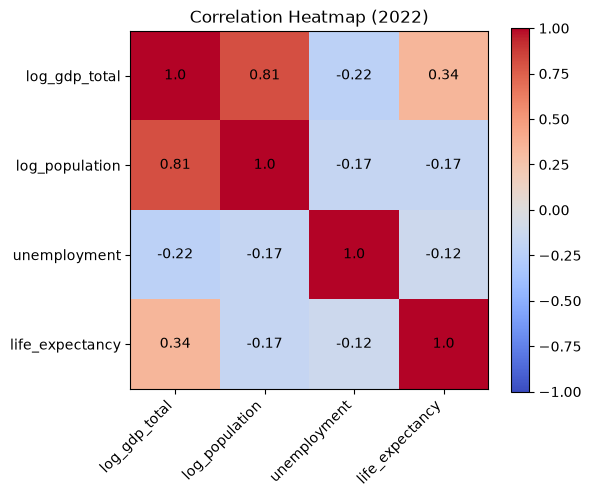

In [26]:
# Correlation heatmap for 2022 (log for GDP and population, as in Q5)
corr_df = latest[["gdp_total", "population", "unemployment", "life_expectancy"]].copy()
corr_df["gdp_total"] = np.log10(corr_df["gdp_total"])
corr_df["population"] = np.log10(corr_df["population"])
corr_df.columns = ["log_gdp_total", "log_population", "unemployment", "life_expectancy"]

corr = corr_df.corr().round(2)
print(corr)

# Heatmap
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, corr.iloc[i, j], ha="center", va="center")
plt.title("Correlation Heatmap (2022)")
plt.tight_layout()
plt.show()